In [3]:
import matplotlib.pyplot as plt
import numpy as np
from utils import makefolder,get_acronym

eps = 1E-7
rcpsize = 17
plt.rcParams['xtick.labelsize']= rcpsize
plt.rcParams['ytick.labelsize']=rcpsize
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'
plt.rcParams['font.size'] = rcpsize
plt.rcParams.update({'figure.autolayout': True})
#colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['ggplot']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8']['axes.prop_cycle'].by_key()['color']
colors = plt.style.library['seaborn-v0_8-dark-palette']['axes.prop_cycle'].by_key()['color']
from cycler import cycler
plt.rcParams['axes.prop_cycle'] = cycler(color=colors)
# print(plt.rcParams.keys())
#np.set_printoptions(precision=None)
markers = ['p','o','h','^','s','*']
_linestyles = ['-','--','dotted']
plot_id = 0

depths = {"deepseek":61,
          "llama":32}

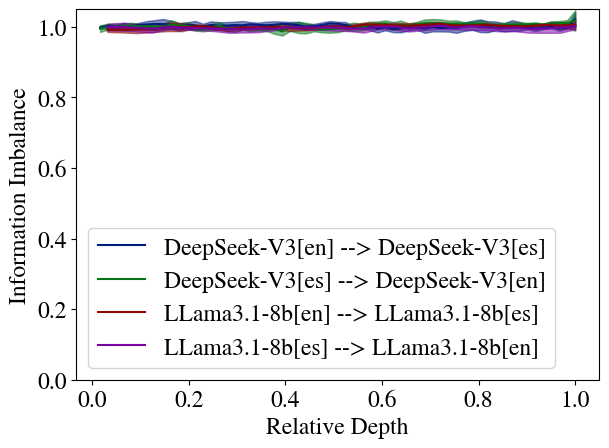

In [4]:
models = [
          'deepseek',
          'llama',
          ]
mask = 2
language_pairs = [('english','spanish'),
                  # ('english','italian'),
                  # ('spanish','italian'),
                  # ('german','hungarian'),
                  ]
n_files = 500

figsfolder = makefolder(base=f'./results/figs/translations/',
                        create_folder=True,
                        n_files=n_files,
                        )

batch_size = 10 
Ns = batch_size*n_files

n_tokens_list = [20]

fig,ax = plt.subplots(1,1,
                            # figsize=(8,6),
                            # constrained_layout=True,
                            )

k_list = [10]
min_token_length = 40
Nbits_list = [1]

seed_list = [0,1,2,3,4]
batch_shuffle = 1
plot_id = 0
for Nbits_id, Nbits in enumerate(Nbits_list):
  for k_id,k in enumerate(k_list):
    for avg in [0]:
      for n_tokens_id,n_tokens in enumerate(n_tokens_list):
        for model_id,model in enumerate(models):
          _model = 'DeepSeek-V3' if model == 'deepseek' else 'LLama3.1-8b'
          for language_pair_id, language_pair in enumerate(language_pairs):
            (languageA,languageB) = language_pair
            IIs = np.zeros(shape=(len(seed_list),2,depths[model]))
            for seed_id, seed in enumerate(seed_list):
              II_folder = makefolder(base=f'./results/santiago/',
                                    batch_shuffle=batch_shuffle,
                                    modelA=model,
                                    modelB=model,
                                    n_files=n_files,
                                    min_token_length=min_token_length,
                                    languageA=languageA,
                                    languageB=languageB,
                                    mask=mask,
                                    k=k,
                                    Nbits=Nbits,
                                    seed=seed,
                                    )
              # alignment = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg_tokens_A}_alignment.npy')
              IIs[seed_id,0,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_AB.npy').diagonal()
              IIs[seed_id,1,:] = np.load(II_folder + f'n_tokens_{n_tokens}_avg_{avg}_BA.npy').diagonal()
            A_layer_ids = np.arange(1,depths[model]+1)
            ax.plot(A_layer_ids/depths[model],
                    IIs[:,0,:].mean(axis=0),
                    label=f'{_model}[{get_acronym(languageA)}] --> {_model}[{get_acronym(languageB)}]',
                    color=colors[plot_id],
                    )
            ax.fill_between(A_layer_ids/depths[model],
                    IIs[:,0,:].mean(axis=0)-IIs[:,0,:].std(axis=0),
                    IIs[:,0,:].mean(axis=0)+IIs[:,0,:].std(axis=0),
                    alpha=0.5,
                    color=colors[plot_id],
                    )
            plot_id += 1
            ax.plot(A_layer_ids/depths[model],
                    IIs[:,1,:].mean(axis=0),
                    color=colors[plot_id],
                    label=f'{_model}[{get_acronym(languageB)}] --> {_model}[{get_acronym(languageA)}]',
                    )
            ax.fill_between(A_layer_ids/depths[model],
                    IIs[:,1,:].mean(axis=0)-IIs[:,1,:].std(axis=0),
                    IIs[:,1,:].mean(axis=0)+IIs[:,1,:].std(axis=0),
                    alpha=0.5,
                    color=colors[plot_id],
                    )
            plot_id += 1
            # ax.plot(A_layer_ids/depths[model],
            #         np.diagonal(alignment),
            #         label=f'A({_model}[{languageB}] <--> {_model}[{languageA}])',
            #         linestyle=_linestyles[model_id],
            #         color=colors[3],
            #         )

ax.set_xlabel('Relative Depth')
ax.set_ylabel('Information Imbalance')
ax.set_ylim(0,1.05)
ax.legend()
# ax.set_title(f'{n_tokens=}')
fig.savefig(f'{figsfolder}misalignment_{n_tokens}.pdf',
            bbox_inches='tight',
            )